**Imports:**

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pathlib import Path
from tqdm.auto import tqdm

print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


**Download Dataset From Zenodo API:**

In [ ]:
RECORD_ID = "23376472"
API = f"https://zenodo.org/api/records/{RECORD_ID}"
DATA_DIR = Path("data/zenodo_colonies")
DATA_DIR.mkdir(parents=True, exist_ok=True)

r = requests.get(API, timeout=60)
r.raise_for_status()
rec = r.json()

print("Title:", rec["metadata"]["title"])
print("DOI:", rec.get("doi"))
files = rec["files"]
print("Remote Files:", len(files))

for f in tqdm(files, desc="Download"):
  name = f["key"]
  url = f["links"]["self"]
  out = DATA_DIR / name
  if out.exists() and out.stat().st_size == f["size"]:
    continue
  resp = requests.get(url, timeout=300)
  resp.raise_for_status()
  out.write_bytes(resp.content)

print("Local Files:", len(list(DATA_DIR.iterdir())))

Title: High-Resolution agar plate image benchmark dataset for automated colony enumeration
DOI: 10.5281/zenodo.23376472
Remote Files: 60


Download:   0%|          | 0/60 [00:00<?, ?it/s]

Local Files: 60


**Load Manifest:**

In [ ]:
manifest_path = DATA_DIR / "manifest.csv"
manifest = pd.read_csv(manifest_path)
manifest["local_path"] = manifest["image_path"].apply(lambda x: str(DATA_DIR / x))
print(manifest.head())
print("\nRows:", len(manifest))
print("Negative Controls:", int(manifest["is_negative_control"].sum()))
print("Media Prefixes:", sorted(set(s.split("_")[0] for s in manifest["sample_id"])))

      image_path sample_id  dilution  volume replicate_id  \
0  MAC_0_01.jpeg     MAC_0       1.0     0.1           r1   
1  MAC_0_02.jpeg     MAC_0       1.0     0.1           r2   
2  MAC_0_03.jpeg     MAC_0       1.0     0.1           r3   
3  MAC_0_04.jpeg     MAC_0       1.0     0.1           r4   
4  MAC_1_01.jpeg     MAC_1       0.1     0.1           r1   

   is_negative_control                          local_path  
0                False  data/zenodo_colonies/MAC_0_01.jpeg  
1                False  data/zenodo_colonies/MAC_0_02.jpeg  
2                False  data/zenodo_colonies/MAC_0_03.jpeg  
3                False  data/zenodo_colonies/MAC_0_04.jpeg  
4                False  data/zenodo_colonies/MAC_1_01.jpeg  

Rows: 59
Negative Controls: 2
Media Prefixes: ['MAC', 'MRS', 'PCA', 'VRBA']


**Helper Functions:**

In [33]:
def resize_max(img, max_side=900):
    h, w = img.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale < 1.0:
        img = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    return img, scale

def find_plate_circle(gray):
    blur = cv2.GaussianBlur(gray, (7, 7), 0)
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8), iterations=2)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not cnts:
        return None

    cnt = max(cnts, key=cv2.contourArea)
    (x, y), r = cv2.minEnclosingCircle(cnt)
    if r < gray.shape[0] * 0.2:
        return None

    return int(x), int(y), int(r)

    edges = cv2.Canny(blur, 50, 150)
    edges = cv2.dilate(edges, np.ones((3, 3), np.uint8), iterations=1)
    cnts, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None
    cnt = max(cnts, key=cv2.contourArea)
    (x, y), r = cv2.minEnclosingCircle(cnt)
    return int(x), int(y), int(r)


def plate_mask(shape, circle, erode_px=18):
    mask = np.zeros(shape[:2], dtype=np.uint8)
    if circle is None:
        mask[:] = 255
        return mask
    x, y, r = circle
    cv2.circle(mask, (x, y), max(1, r - erode_px), 255, -1)
    return mask


def show_bgr(img, title="", ax=None):
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if ax is None:
        plt.imshow(rgb)
        plt.title(title)
        plt.axis("off")
    else:
        ax.imshow(rgb)
        ax.set_title(title)
        ax.axis("off")

**Quick Test On A Few Images:**

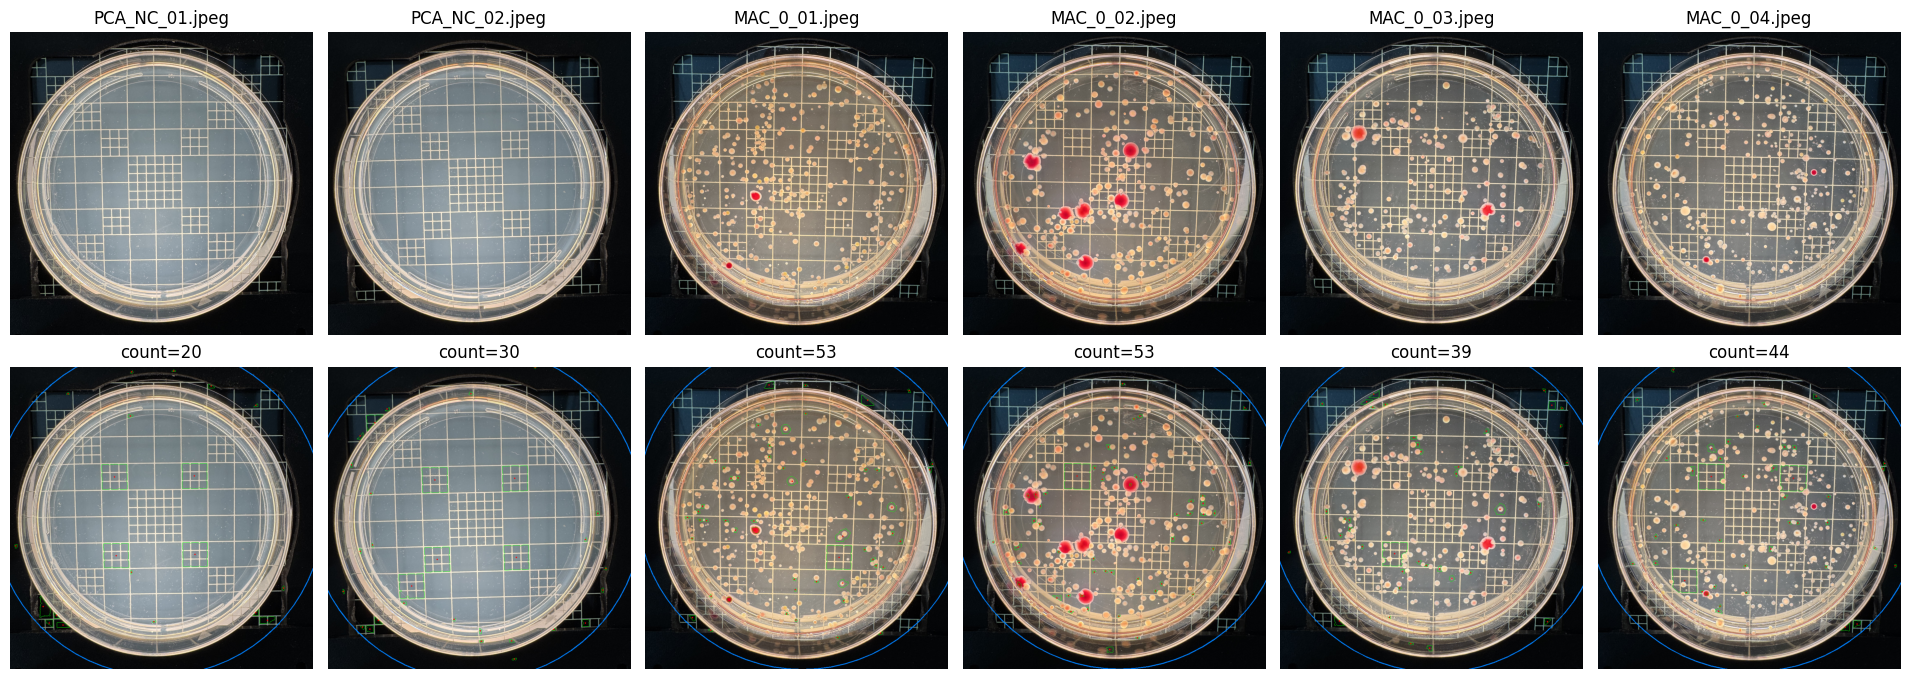

,image_path,sample_id,is_negative_control,pred_count
0,PCA_NC_01.jpeg,PCA_NC,True,20
1,PCA_NC_02.jpeg,PCA_NC,True,30
2,MAC_0_01.jpeg,MAC_0,False,53
3,MAC_0_02.jpeg,MAC_0,False,53
4,MAC_0_03.jpeg,MAC_0,False,39
5,MAC_0_04.jpeg,MAC_0,False,44


In [34]:
def count_colonies(img_bgr, min_area=35, max_area_ratio=0.01, min_circularity=0.45):
    work, scale = resize_max(img_bgr, 900)
    gray = cv2.cvtColor(work, cv2.COLOR_BGR2GRAY)
    circle = find_plate_circle(gray)
    mask = plate_mask(work.shape, circle, erode_px=16)

    binary_lines = cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY_INV, 15, 7
    )
    horizontal = cv2.morphologyEx(
        binary_lines, cv2.MORPH_OPEN,
        cv2.getStructuringElement(cv2.MORPH_RECT, (25, 1)), iterations=1
    )
    vertical = cv2.morphologyEx(
        binary_lines, cv2.MORPH_OPEN,
        cv2.getStructuringElement(cv2.MORPH_RECT, (1, 25)), iterations=1
    )
    grid = cv2.bitwise_or(horizontal, vertical)
    grid = cv2.dilate(grid, np.ones((3, 3), np.uint8), iterations=1)

    blur_bg = cv2.GaussianBlur(gray, (0, 0), 21)
    norm = cv2.divide(gray, blur_bg, scale=128)

    hsv = cv2.cvtColor(work, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]
    color_boost = cv2.normalize(sat, None, 0, 255, cv2.NORM_MINMAX)

    mix = cv2.addWeighted(norm, 0.7, color_boost, 0.3, 0)
    mix = cv2.bitwise_and(mix, mix, mask=mask)

    thr = cv2.adaptiveThreshold(
        mix, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, 31, 4
    )
    thr = cv2.bitwise_and(thr, thr, mask=mask)
    thr = cv2.bitwise_and(thr, cv2.bitwise_not(grid))

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    bin_img = cv2.morphologyEx(thr, cv2.MORPH_OPEN, kernel, iterations=1)
    bin_img = cv2.morphologyEx(bin_img, cv2.MORPH_CLOSE, kernel, iterations=2)

    cnts, _ = cv2.findContours(bin_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    plate_area = float(mask.sum() / 255.0) + 1.0
    max_area = plate_area * max_area_ratio

    overlay = work.copy()
    kept = 0
    for c in cnts:
        area = cv2.contourArea(c)
        if area < min_area or area > max_area:
            continue
        peri = cv2.arcLength(c, True) + 1e-6
        circ = 4 * np.pi * area / (peri * peri)
        if circ < min_circularity:
            continue
        x, y, w, h = cv2.boundingRect(c)
        if max(w, h) / (min(w, h) + 1e-6) > 2.5:
            continue
        hull = cv2.convexHull(c)
        if area / (cv2.contourArea(hull) + 1e-6) < 0.6:
            continue

        kept += 1
        cv2.drawContours(overlay, [c], -1, (0, 255, 0), 1)
        (cx, cy), _ = cv2.minEnclosingCircle(c)
        cv2.circle(overlay, (int(cx), int(cy)), 2, (0, 0, 255), -1)

    if circle is not None:
        x, y, r = circle
        cv2.circle(overlay, (x, y), r, (255, 128, 0), 2)

    return kept, overlay, {"circle": circle, "grid": grid, "binary": bin_img}


samples = pd.concat([
    manifest[manifest["is_negative_control"] == True].head(2),
    manifest[manifest["is_negative_control"] == False].head(4)
], ignore_index=True)

fig, axes = plt.subplots(2, len(samples), figsize=(3.2 * len(samples), 7))
results = []
for i, row in samples.iterrows():
    img = cv2.imread(row["local_path"])
    count, overlay, _ = count_colonies(img)
    results.append({
        "image_path": row["image_path"],
        "sample_id": row["sample_id"],
        "is_negative_control": row["is_negative_control"],
        "pred_count": count,
    })
    show_bgr(img, row["image_path"], ax=axes[0, i])
    show_bgr(overlay, f"count={count}", ax=axes[1, i])

plt.tight_layout()
plt.show()

pd.DataFrame(results)

**Run On Full Dataset:**

In [ ]:
rows = []

for _, row in tqdm(manifest.iterrows(), total=len(manifest)):
    img = cv2.imread(row["local_path"])
    if img is None:
        rows.append({**row.to_dict(), "pred_count": None, "error": "read_fail"})
        continue

    try:
        count, overlay, _ = count_colonies(img)
        out_ov = DATA_DIR / "overlays"
        out_ov.mkdir(exist_ok=True)
        cv2.imwrite(str(out_ov / row["image_path"]), overlay)
        rows.append({**row.to_dict(), "pred_count": count, "error": ""})

    except Exception as e:
        rows.append({**row.to_dict(), "pred_count": None, "error": str(e)})

results_df = pd.DataFrame(rows)
results_df.to_csv(DATA_DIR / "colony_counts.csv", index=False)

print(results_df[["image_path", "sample_id", "is_negative_control", "pred_count", "error"]].head(15))
print("\nSaved:", DATA_DIR / "colony_counts.csv")

nc = results_df[results_df["is_negative_control"] == True]["pred_count"]
pos = results_df[results_df["is_negative_control"] == False]["pred_count"]
print("Mean Count (Non-NC):", pos.mean())
print("Mean Count (NC):", nc.mean())
print("NC Rows:\n", results_df.loc[results_df["is_negative_control"] == True, ["image_path", "pred_count"]])

  0%|          | 0/59 [00:00<?, ?it/s]

       image_path sample_id  is_negative_control  pred_count error
0   MAC_0_01.jpeg     MAC_0                False          53      
1   MAC_0_02.jpeg     MAC_0                False          53      
2   MAC_0_03.jpeg     MAC_0                False          39      
3   MAC_0_04.jpeg     MAC_0                False          44      
4   MAC_1_01.jpeg     MAC_1                False          55      
5   MAC_1_02.jpeg     MAC_1                False          34      
6   MAC_1_03.jpeg     MAC_1                False          40      
7   MAC_1_04.jpeg     MAC_1                False          62      
8   MAC_2_01.jpeg     MAC_2                False          29      
9   MAC_2_02.jpeg     MAC_2                False          34      
10  MAC_3_01.jpeg     MAC_3                False          37      
11  MAC_3_02.jpeg     MAC_3                False          31      
12  MRS_0_01.jpeg     MRS_0                False          39      
13  MRS_0_02.jpeg     MRS_0                False          43  

**Simple Summary Plot:**

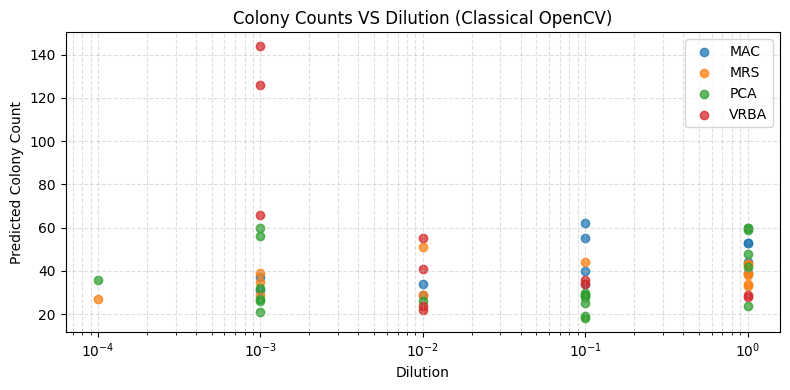

In [ ]:
plot_df = results_df.dropna(subset=["pred_count"]).copy()
plot_df["media"] = plot_df["sample_id"].str.split("_").str[0]

fig, ax = plt.subplots(figsize=(8, 4))
for media, g in plot_df.groupby("media"):
  ax.scatter(g["dilution"], g["pred_count"], label=media, alpha=0.75)
ax.set_xscale("log")
ax.set_xlabel("Dilution")
ax.set_ylabel("Predicted Colony Count")
ax.set_title("Colony Counts VS Dilution (Classical OpenCV)")
ax.legend()
ax.grid(True, which="both", ls="--", alpha=0.4)

plt.tight_layout()
plt.show()